# Phase 2 Task 5: ResNet-50 Backbone LR Tuning

**Objective:** Tune backbone LR from 1e-5 to 1e-4 for ResNet-50

**Date:** 30-09-2026

**Features:**
- Auto-resume from checkpoint if exists
- num_workers=0 (avoids Jupyter multiprocessing error)
- Save final model even if training interrupted

## 1. Setup

In [15]:
from pathlib import Path
import sys

CWD = Path.cwd()
for i, part in enumerate(CWD.parts):
    if part == 'woodbench':
        ROOT = Path(*CWD.parts[:i+1])
        break
else:
    ROOT = CWD

sys.path.insert(0, str(ROOT))

import torch
import timm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

print(f"ROOT: {ROOT}")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

ROOT: /home/sakana/Code/ManifoldsTeam/woodbench
PyTorch: 2.12.0+cu130
CUDA: True
GPU: NVIDIA GeForce RTX 3060


## 2. Configuration

In [16]:
CONFIG = {
    'backbone': 'resnet50',
    'backbone_lr': 1e-4,
    'head_lr': 1e-4,
    'weight_decay': 1e-4,
    'epochs': 50,
    'batch_size': 64,
    'label_smoothing': 0.1,
    'seed': 42,
    'num_workers': 4,  # Required for Jupyter (avoids AssertionError)
}

DATA_DIR = ROOT / "data" / "task-B-group-split"
OUTPUT_DIR = ROOT / "data" / "experiments" / "Task-B-new" / "lr_tuning"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = OUTPUT_DIR / 'resnet50_lr1e-4_best.pth'
FINAL_PATH = OUTPUT_DIR / 'resnet50_lr1e-4_final.pth'

print("Config:")
for k, v in CONFIG.items():
    print(f"  {k}: {v}")
print(f"\nCheckpoint: {CHECKPOINT_PATH}")
print(f"Checkpoint exists: {CHECKPOINT_PATH.exists()}")

Config:
  backbone: resnet50
  backbone_lr: 0.0001
  head_lr: 0.0001
  weight_decay: 0.0001
  epochs: 50
  batch_size: 64
  label_smoothing: 0.1
  seed: 42
  num_workers: 4

Checkpoint: /home/sakana/Code/ManifoldsTeam/woodbench/data/experiments/Task-B-new/lr_tuning/resnet50_lr1e-4_best.pth
Checkpoint exists: True


## 3. Dataset

In [17]:
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader

class FlatDataset(Dataset):
    def __init__(self, root_dir, split, transform=None):
        self.root_dir = Path(root_dir)
        self.split = split
        self.transform = transform
        
        self.samples = []
        self.classes = sorted([d.name for d in (self.root_dir / split).iterdir() if d.is_dir()])
        self.class_to_idx = {c: i for i, c in enumerate(self.classes)}
        
        for class_name in self.classes:
            class_dir = self.root_dir / split / class_name
            for img_path in class_dir.glob("*.png"):
                self.samples.append((str(img_path), self.class_to_idx[class_name]))
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        img = Image.open(img_path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, label

train_transform = T.Compose([
    T.RandomResizedCrop(224, scale=(0.8, 1.0)),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.RandomRotation(90),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = T.Compose([
    T.Resize(256),
    T.CenterCrop(224),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = FlatDataset(DATA_DIR, 'train', transform=train_transform)
val_dataset = FlatDataset(DATA_DIR, 'val', transform=val_transform)
test_dataset = FlatDataset(DATA_DIR, 'test', transform=val_transform)

print(f"Train: {len(train_dataset)}, Val: {len(val_dataset)}, Test: {len(test_dataset)}")
print(f"Classes: {len(train_dataset.classes)}")

Train: 3365, Val: 903, Test: 532
Classes: 17


## 4. Model & Optimizer

In [18]:
num_classes = len(train_dataset.classes)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Create fresh model
model = timm.create_model('resnet50', pretrained=True, num_classes=num_classes)
model = model.to(device)

# Differential LR setup
backbone_params = []
head_params = []
for name, param in model.named_parameters():
    if 'fc' in name or 'classifier' in name:
        head_params.append(param)
    else:
        backbone_params.append(param)

optimizer = torch.optim.AdamW([
    {'params': backbone_params, 'lr': CONFIG['backbone_lr']},
    {'params': head_params, 'lr': CONFIG['head_lr']},
], weight_decay=CONFIG['weight_decay'])

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG['epochs'])
criterion = torch.nn.CrossEntropyLoss(label_smoothing=CONFIG['label_smoothing'])

# Initialize training state
start_epoch = 0
best_val_acc = 0
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

# Auto-resume from checkpoint if exists
if CHECKPOINT_PATH.exists():
    print(f"\n📂 Loading checkpoint from {CHECKPOINT_PATH}...")
    try:
        checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
        
        if 'model_state_dict' in checkpoint:
            model.load_state_dict(checkpoint['model_state_dict'])
            start_epoch = checkpoint.get('epoch', 0) + 1
            best_val_acc = checkpoint.get('best_val_acc', 0)
            
            if 'history' in checkpoint:
                history = checkpoint['history']
            
            if 'optimizer_state_dict' in checkpoint:
                try:
                    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
                except:
                    pass
            
            # Update scheduler to remaining epochs
            remaining_epochs = CONFIG['epochs'] - start_epoch
            if remaining_epochs > 0:
                scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=remaining_epochs)
            
            print(f"   ✅ Resumed from epoch {start_epoch}")
            print(f"   Best val acc so far: {best_val_acc:.4f}")
            print(f"   History loaded: {len(history['train_loss'])} epochs")
        else:
            print("   ⚠️ Checkpoint doesn't have model_state_dict, starting fresh")
    except Exception as e:
        print(f"   ❌ Error loading checkpoint: {e}")
        print("   Starting fresh training")
else:
    print("\n🆕 No checkpoint found, starting fresh training")

print(f"\nTraining from epoch {start_epoch+1} to {CONFIG['epochs']}")


📂 Loading checkpoint from /home/sakana/Code/ManifoldsTeam/woodbench/data/experiments/Task-B-new/lr_tuning/resnet50_lr1e-4_best.pth...
   ✅ Resumed from epoch 15
   Best val acc so far: 0.9435
   History loaded: 0 epochs

Training from epoch 16 to 50


## 5. Dataloaders

In [19]:
train_loader = DataLoader(
    train_dataset, batch_size=CONFIG['batch_size'], shuffle=True,
    num_workers=CONFIG['num_workers'], pin_memory=True
)
val_loader = DataLoader(
    val_dataset, batch_size=CONFIG['batch_size'], shuffle=False,
    num_workers=CONFIG['num_workers'], pin_memory=True
)
test_loader = DataLoader(
    test_dataset, batch_size=CONFIG['batch_size'], shuffle=False,
    num_workers=CONFIG['num_workers'], pin_memory=True
)

torch.manual_seed(CONFIG['seed'])
np.random.seed(CONFIG['seed'])

print(f"Train batches: {len(train_loader)}")
print(f"Val batches: {len(val_loader)}")
print(f"Test batches: {len(test_loader)}")

Train batches: 53
Val batches: 15
Test batches: 9


## 6. Training Functions

In [20]:
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    
    for images, labels in tqdm(loader, desc='Training'):
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item() * images.size(0)
        _, preds = outputs.max(1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    
    return total_loss / total, correct / total

def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for images, labels in tqdm(loader, desc='Evaluating'):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            total_loss += loss.item() * images.size(0)
            _, preds = outputs.max(1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    
    return total_loss / total, correct / total

print("Functions defined")

Functions defined


## 7. Run Training (with auto-resume)

In [21]:
print(f"\n{'='*60}")
print(f"Training from epoch {start_epoch+1} to {CONFIG['epochs']}")
print(f"Backbone LR: {CONFIG['backbone_lr']}")
print(f"{'='*60}\n")

for epoch in range(start_epoch, CONFIG['epochs']):
    # Train
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
    
    # Validate
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)
    
    # Update scheduler
    scheduler.step()
    
    # Save history
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    
    # Save best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_val_acc': best_val_acc,
            'history': history,
            'config': CONFIG
        }, CHECKPOINT_PATH)
        marker = " ★ BEST"
    else:
        marker = ""
    
    # Print progress
    if (epoch + 1) % 5 == 0 or marker or epoch == start_epoch:
        print(f"Epoch {epoch+1:3d}/{CONFIG['epochs']}: Train Loss={train_loss:.4f}, Train Acc={train_acc:.4f}, Val Loss={val_loss:.4f}, Val Acc={val_acc:.4f}{marker}")

print(f"\n{'='*60}")
print(f"Training complete! Best val accuracy: {best_val_acc:.4f}")
print(f"{'='*60}")


Training from epoch 16 to 50
Backbone LR: 0.0001



Training:   0%|          | 0/53 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/15 [00:00<?, ?it/s]

Epoch  16/50: Train Loss=0.6733, Train Acc=0.9703, Val Loss=0.7408, Val Acc=0.9424


Training:   0%|          | 0/53 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/15 [00:00<?, ?it/s]

... (79 outputs left out)

Evaluating:   0%|          | 0/15 [00:00<?, ?it/s]

Training:   0%|          | 0/53 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/15 [00:00<?, ?it/s]

Epoch  50/50: Train Loss=0.6159, Train Acc=0.9896, Val Loss=0.6919, Val Acc=0.9524

Training complete! Best val accuracy: 0.9612


## 8. Save Final Model

In [22]:
# Save final model
torch.save({
    'epoch': CONFIG['epochs'],
    'model_state_dict': model.state_dict(),
    'best_val_acc': best_val_acc,
    'history': history,
    'config': CONFIG
}, FINAL_PATH)
print(f"Final model saved: {FINAL_PATH}")

Final model saved: /home/sakana/Code/ManifoldsTeam/woodbench/data/experiments/Task-B-new/lr_tuning/resnet50_lr1e-4_final.pth


## 9. Plot Training Curves

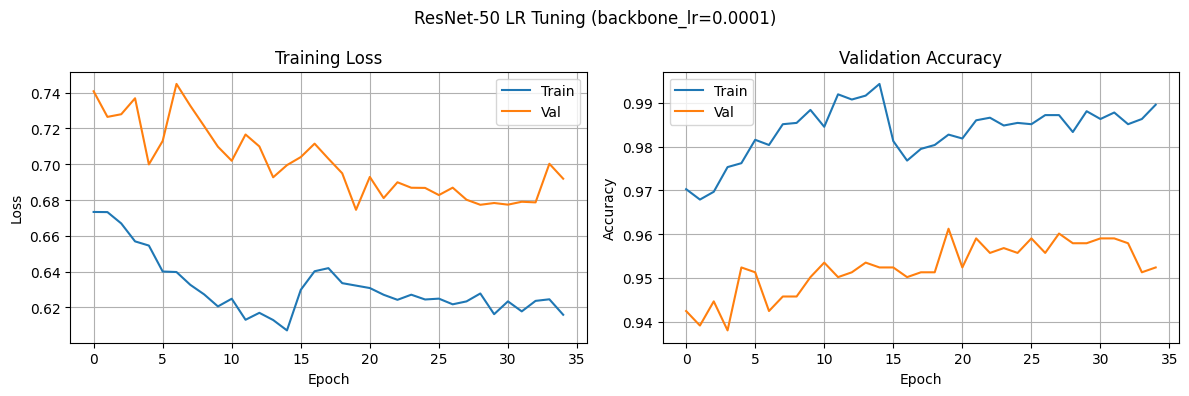

In [23]:
if len(history['train_loss']) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    axes[0].plot(history['train_loss'], label='Train')
    axes[0].plot(history['val_loss'], label='Val')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title('Training Loss')
    axes[0].legend()
    axes[0].grid(True)
    
    axes[1].plot(history['train_acc'], label='Train')
    axes[1].plot(history['val_acc'], label='Val')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].set_title('Validation Accuracy')
    axes[1].legend()
    axes[1].grid(True)
    
    plt.suptitle(f"ResNet-50 LR Tuning (backbone_lr={CONFIG['backbone_lr']})")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'training_curves.png', dpi=150)
    plt.show()
else:
    print("No training history available")

## 10. Evaluate on Test Set

In [24]:
test_loss, test_acc = evaluate(model, test_loader, criterion, device)

print(f"\n=== Test Set Results ===")
print(f"Accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)")

# Per-class metrics
from sklearn.metrics import classification_report, confusion_matrix

model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc='Test'):
        images = images.to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=test_dataset.classes))

Evaluating:   0%|          | 0/9 [00:00<?, ?it/s]


=== Test Set Results ===
Accuracy: 0.9605 (96.05%)


Test:   0%|          | 0/9 [00:00<?, ?it/s]


Classification Report:
                            precision    recall  f1-score   support

        Araucaria araucana       1.00      1.00      1.00        30
    Callitris columellaris       1.00      0.94      0.97        34
      Calocedrus rupestris       1.00      1.00      1.00        24
      Chamaecyparis obtusa       1.00      1.00      1.00        33
      Cryptomeria japonica       1.00      1.00      1.00        33
   Cunninghamia lanceolata       0.93      1.00      0.96        27
        Fokienia hodginsii       1.00      1.00      1.00        39
              Picea glauca       0.96      1.00      0.98        25
              Pinus cernua       0.97      0.94      0.95        31
          Pinus dalatensis       0.88      0.94      0.91        32
            Pinus krempfii       0.91      0.89      0.90        36
             Pinus radiata       1.00      1.00      1.00        31
        Podocarpus pilgeri       0.88      0.83      0.86        36
    Pseudotsuga brevifo

## 11. Compare with Original ResNet-50

In [25]:
original_test_acc = 0.93672  # ResNet-50 main seed 42 (backbone_lr=1e-5)

print("=== Comparison: Original vs LR-Tuned ResNet-50 ===")
print(f"Original (backbone_lr=1e-5):  {original_test_acc:.4f} ({original_test_acc*100:.2f}%)")
print(f"New (backbone_lr={CONFIG['backbone_lr']}):    {test_acc:.4f} ({test_acc*100:.2f}%)")
print(f"Difference: {(test_acc - original_test_acc)*100:+.2f}%")

if test_acc > original_test_acc:
    print("\n✅ Higher LR improved performance!")
else:
    print("\n⚠️ Higher LR did not improve performance")

=== Comparison: Original vs LR-Tuned ResNet-50 ===
Original (backbone_lr=1e-5):  0.9367 (93.67%)
New (backbone_lr=0.0001):    0.9605 (96.05%)
Difference: +2.38%

✅ Higher LR improved performance!


## 12. Save Results

In [26]:
import json

results = {
    'backbone': CONFIG['backbone'],
    'seed': CONFIG['seed'],
    'backbone_lr': CONFIG['backbone_lr'],
    'head_lr': CONFIG['head_lr'],
    'epochs_trained': len(history['train_loss']),
    'best_val_acc': best_val_acc,
    'test_accuracy': test_acc,
    'original_test_accuracy': original_test_acc,
    'improvement': test_acc - original_test_acc,
}

with open(OUTPUT_DIR / 'test_metrics.json', 'w') as f:
    json.dump(results, f, indent=2)

pd.DataFrame(history).to_csv(OUTPUT_DIR / 'training_history.csv', index=False)

print(f"Results saved to: {OUTPUT_DIR}")
print(json.dumps(results, indent=2))

Results saved to: /home/sakana/Code/ManifoldsTeam/woodbench/data/experiments/Task-B-new/lr_tuning
{
  "backbone": "resnet50",
  "seed": 42,
  "backbone_lr": 0.0001,
  "head_lr": 0.0001,
  "epochs_trained": 35,
  "best_val_acc": 0.9612403100775194,
  "test_accuracy": 0.9605263157894737,
  "original_test_accuracy": 0.93672,
  "improvement": 0.023806315789473675
}
